# Causal Inference for Machine Learning

Predictive models learn associations. Causal questions ask what happens when we **intervene**: does a
drug improve recovery, does an ad campaign increase sales, does a policy reduce churn? A model with
high accuracy can still give the wrong answer to a causal question because of confounding.

This notebook introduces the core ideas with simulated experiments and observational data.

## Learning objectives

By the end of this notebook you can:

- distinguish prediction from causal effect estimation;
- define potential outcomes, ATE, and ATT;
- explain confounding and the backdoor criterion;
- estimate effects from randomized experiments;
- adjust for observed confounders with regression, stratification, and propensity scores;
- use difference-in-differences for panel data;
- state the assumptions required for a causal claim.

## 1. Prediction is not causation

Suppose older and sicker patients are more likely to receive a treatment, and they also have worse
outcomes. A naive comparison of treated and untreated patients can make the treatment look harmful
even if it helps.

The causal question is:

> What would the outcome have been for the same patient with and without treatment?

We only observe one of those two potential outcomes, which is the fundamental problem of causal
inference.

## 2. Potential outcomes and estimands

For each unit $i$, define:

- $Y_i(1)$: outcome if treated;
- $Y_i(0)$: outcome if untreated.

The individual treatment effect is $Y_i(1) - Y_i(0)$, which is never observed. We estimate averages:

- **ATE:** $E[Y(1) - Y(0)]$, the average effect for the population;
- **ATT:** $E[Y(1) - Y(0) \mid T=1]$, the average effect for the treated.

Randomization makes treatment independent of potential outcomes, so a difference in means estimates
the ATE. Observational data requires adjustment under explicit assumptions.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression, LogisticRegression

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## 3. A randomized experiment

We simulate an RCT with 2,000 patients. Treatment is assigned by a coin flip, so treated and control
groups are balanced in expectation. The true treatment effect is 2.0 points.

In [2]:
n = 2000
age = rng.normal(45, 12, n)
severity = rng.normal(0, 1, n)
treatment_rct = rng.binomial(1, 0.5, n)
outcome_rct = 5 + 2.0 * treatment_rct + 0.1 * age + 1.5 * severity + rng.normal(0, 1, n)

rct = pd.DataFrame({
    "treatment": treatment_rct,
    "age": age,
    "severity": severity,
    "outcome": outcome_rct,
})

naive_rct = rct.loc[rct.treatment == 1, "outcome"].mean() -             rct.loc[rct.treatment == 0, "outcome"].mean()
print("naive difference in means (RCT):", round(naive_rct, 3))
print("true effect: 2.0")

naive difference in means (RCT): 2.056
true effect: 2.0


In [3]:
rct_model = smf.ols("outcome ~ treatment + age + severity", data=rct).fit()
print("adjusted treatment coefficient:", round(rct_model.params["treatment"], 3))
print("95% CI:", np.round(rct_model.conf_int().loc["treatment"].values, 3))

adjusted treatment coefficient: 2.03
95% CI: [1.942 2.118]


In an RCT the unadjusted difference is already unbiased; adjustment can improve precision by
explaining outcome variance. The confidence interval quantifies sampling uncertainty, not bias from
unmeasured confounding.

## 4. Observational data and confounding

Now treatment is not randomized. Older and sicker patients are more likely to receive it, and both
also affect the outcome. This creates a **backdoor path** from treatment to outcome through the
confounders.

A directed acyclic graph (DAG) for this setting is:

```
age, severity  ->  treatment
age, severity  ->  outcome
treatment      ->  outcome
```

To identify the causal effect, we must block the backdoor path by adjusting for age and severity.

In [4]:
treatment_prob = 1 / (1 + np.exp(-(0.06 * (age - 45) + 0.9 * severity)))
treatment_obs = rng.binomial(1, treatment_prob)
outcome_obs = 5 + 2.0 * treatment_obs + 0.1 * age + 1.5 * severity + rng.normal(0, 1, n)

obs = pd.DataFrame({
    "treatment": treatment_obs,
    "age": age,
    "severity": severity,
    "outcome": outcome_obs,
})

naive_obs = obs.loc[obs.treatment == 1, "outcome"].mean() -             obs.loc[obs.treatment == 0, "outcome"].mean()
print("naive difference in means (observational):", round(naive_obs, 3))
print("true effect: 2.0")
print("treated mean age:", round(obs.loc[obs.treatment == 1, "age"].mean(), 2))
print("control mean age:", round(obs.loc[obs.treatment == 0, "age"].mean(), 2))

naive difference in means (observational): 3.743
true effect: 2.0
treated mean age: 47.87
control mean age: 40.59


The naive estimate is biased upward because treated patients are older and sicker, and those factors
also increase the outcome. Adjustment cannot fix confounding that was not measured, so the choice of
covariates must come from domain knowledge, not just from what is in the dataset.

In [5]:
model_age_only = smf.ols("outcome ~ treatment + age", data=obs).fit()
model_adjusted = smf.ols("outcome ~ treatment + age + severity", data=obs).fit()

print("adjusting for age only:      ", round(model_age_only.params["treatment"], 3))
print("adjusting for age + severity:", round(model_adjusted.params["treatment"], 3))
print("true effect:                  2.0")

adjusting for age only:       3.119
adjusting for age + severity: 2.002
true effect:                  2.0


Adjusting for age alone leaves the severity backdoor open, so the estimate remains biased. Adjusting
for both observed confounders recovers the true effect in this simulation. In practice we never know
that all confounders are measured; sensitivity analysis is essential.

## 5. Stratification

Another way to adjust is to compare treated and control units **within strata** that have similar
confounder values, then average the within-stratum differences. We bin age into quartiles and
severity into low/high groups.

In [6]:
obs["age_bin"] = pd.qcut(obs["age"], 4, labels=False)
obs["severity_bin"] = pd.qcut(obs["severity"], 2, labels=False)
obs["stratum"] = obs["age_bin"].astype(str) + "_" + obs["severity_bin"].astype(str)

stratum_effects = []
stratum_sizes = []
for _, group in obs.groupby("stratum"):
    treated = group.loc[group.treatment == 1, "outcome"]
    control = group.loc[group.treatment == 0, "outcome"]
    if len(treated) > 5 and len(control) > 5:
        stratum_effects.append(treated.mean() - control.mean())
        stratum_sizes.append(len(group))

stratified_estimate = np.average(stratum_effects, weights=stratum_sizes)
print("stratified estimate:", round(stratified_estimate, 3))
print("number of usable strata:", len(stratum_effects))

stratified estimate: 2.56
number of usable strata: 8


Stratification is transparent but becomes impractical with many confounders (the curse of
dimensionality). Propensity scores summarize the confounders into a single balancing score.

## 6. Propensity scores and inverse probability weighting

The propensity score is the probability of treatment given observed covariates:

$$ e(X) = P(T=1 \mid X) $$

If treatment is independent of potential outcomes within levels of $X$ (conditional exchangeability),
then adjusting for $e(X)$ is sufficient. **Inverse probability weighting (IPW)** weights treated
units by $1/e(X)$ and controls by $1/(1-e(X))$:

$$ \widehat{\mathrm{ATE}} = \frac{1}{n} \sum_i
\left( \frac{T_i Y_i}{e(X_i)} - \frac{(1-T_i)Y_i}{1-e(X_i)} \right) $$

In [7]:
features = ["age", "severity"]
propensity_model = LogisticRegression(max_iter=1000)
propensity_model.fit(obs[features], obs["treatment"])
obs["propensity"] = propensity_model.predict_proba(obs[features])[:, 1]

obs["ipw"] = np.where(
    obs["treatment"] == 1,
    1 / obs["propensity"],
    1 / (1 - obs["propensity"])
)
ipw_estimate = np.mean(
    obs["treatment"] * obs["outcome"] / obs["propensity"]
    - (1 - obs["treatment"]) * obs["outcome"] / (1 - obs["propensity"])
)

print("propensity range:", np.round([obs.propensity.min(), obs.propensity.max()], 3))
print("IPW estimate:", round(ipw_estimate, 3))
print("true effect:  2.0")

propensity range: [0.023 0.97 ]
IPW estimate: 2.201
true effect:  2.0


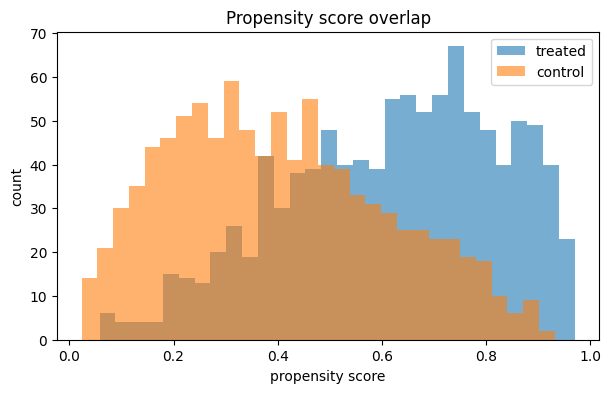

In [8]:
plt.figure(figsize=(7, 4))
plt.hist(obs.loc[obs.treatment == 1, "propensity"], bins=30, alpha=0.6, label="treated")
plt.hist(obs.loc[obs.treatment == 0, "propensity"], bins=30, alpha=0.6, label="control")
plt.xlabel("propensity score")
plt.ylabel("count")
plt.title("Propensity score overlap")
plt.legend()
plt.show()

Overlap is important: if some treated units have propensity near 1 and some controls near 0, the
weighted estimate relies on a few extreme weights. Common checks include trimming extreme
propensities, stabilizing weights, and comparing weighted covariate balance.

## 7. Difference-in-differences

Difference-in-differences (DiD) is useful when treatment is introduced at a different time for one
group, and we observe both groups before and after. It compares the change in the treated group with
the change in the control group:

$$ \widehat{\tau}_{DiD} =
(\bar{Y}_{T,\text{post}} - \bar{Y}_{T,\text{pre}})
- (\bar{Y}_{C,\text{post}} - \bar{Y}_{C,\text{pre}}) $$

The key assumption is **parallel trends**: without treatment, the two groups would have followed the
same trend.

In [9]:
units = 600
group = rng.binomial(1, 0.5, units)
unit_effect = rng.normal(0, 1.5, units)
pre = 20 + 3 * group + unit_effect + rng.normal(0, 1, units)
post = 24 + 3 * group + 2 * group + unit_effect + rng.normal(0, 1, units)

panel = pd.concat([
    pd.DataFrame({"unit": np.arange(units), "group": group,
                  "post": 0, "outcome": pre}),
    pd.DataFrame({"unit": np.arange(units), "group": group,
                  "post": 1, "outcome": post}),
], ignore_index=True)

did_manual = (
    panel.query("group == 1 and post == 1").outcome.mean()
    - panel.query("group == 1 and post == 0").outcome.mean()
    - panel.query("group == 0 and post == 1").outcome.mean()
    + panel.query("group == 0 and post == 0").outcome.mean()
)
print("manual DiD estimate:", round(did_manual, 3))
print("true treatment effect: 2.0")

manual DiD estimate: 2.088
true treatment effect: 2.0


In [10]:
did_model = smf.ols("outcome ~ group + post + group:post", data=panel).fit()
print("regression DiD interaction:", round(did_model.params["group:post"], 3))
print("95% CI:", np.round(did_model.conf_int().loc["group:post"].values, 3))

regression DiD interaction: 2.088
95% CI: [1.678 2.499]


The interaction coefficient is the DiD estimate. It is valid only if the parallel-trends assumption
holds. Plotting pre-treatment trends and checking for anticipation effects are standard checks.

## 8. What causal inference requires

Causal claims need assumptions that cannot be tested from the data alone:

- **Consistency:** the observed treatment corresponds to a well-defined intervention.
- **Exchangeability:** no unmeasured confounding, possibly conditional on covariates.
- **Positivity:** every unit has a positive probability of each treatment level.
- **No interference:** one unit's treatment does not affect another's outcome.
- **Correct functional form / model specification** when using regression or propensity models.

Machine learning can help estimate nuisance functions such as propensity scores or outcome models,
but it cannot create identification. If the design is wrong, a better predictor will not fix it.

## 9. Summary

- Prediction answers "what is associated with the outcome?"; causal inference answers "what happens
  if we intervene?"
- Confounding creates backdoor paths that must be blocked by design or adjustment.
- Randomized experiments identify the ATE via exchangeability.
- Regression, stratification, and propensity-score weighting adjust for observed confounders.
- DiD uses parallel trends instead of conditional exchangeability.
- Every causal estimate depends on assumptions; report them and test what you can.

## Exercises

1. Change the treatment-assignment coefficients so that age matters more than severity. How does the
   naive estimate change?
2. Add a variable that affects only the outcome (not treatment). Does including it change the
   treatment estimate?
3. Compare IPW with and without trimming propensities below 0.05 and above 0.95.
4. Simulate a violation of parallel trends and show how DiD becomes biased.
5. Explain why a high-accuracy outcome model does not guarantee an unbiased treatment effect.